# 35 · Operational-space control and Cartesian impedance

In [1]:
import mujoco, numpy as np, matplotlib.pyplot as plt
from vlacourse import torque_panda, show_video
from vlacourse.panda import pose_error

HOME = np.array([0, 0, 0, -1.571, 0, 1.571, -0.785])

def full_M(model, data):
    M = np.zeros((model.nv, model.nv)); mujoco.mj_fullM(model, data, M)
    return M[:7, :7]

def jac(model, data):
    jp, jr = np.zeros((3, model.nv)), np.zeros((3, model.nv))
    mujoco.mj_jacSite(model, data, jp, jr, model.site("ee").id)
    return np.vstack([jp, jr])[:, :7]

def osc_torque(model, data, x_d, xd_d, xdd_d, quat_d, Kp, Kd, null_kp=10.0, dynamic=True):
    M, J = full_M(model, data), jac(model, data)
    quat = np.zeros(4); mujoco.mju_mat2Quat(quat, data.site("ee").xmat)
    e = pose_error(x_d, quat_d, data.site("ee").xpos, quat)
    v = J @ data.qvel[:7]
    a_cmd = np.r_[xdd_d, np.zeros(3)] + Kp * e + Kd * (np.r_[xd_d, np.zeros(3)] - v)
    if dynamic:
        Minv = np.linalg.inv(M)
        Lam = np.linalg.inv(J @ Minv @ J.T + 1e-4 * np.eye(6))
        F = Lam @ a_cmd
        Jbar = Minv @ J.T @ Lam
        N = np.eye(7) - J.T @ Jbar.T
    else:
        F = a_cmd
        N = np.eye(7) - np.linalg.pinv(J) @ J
    tau_null = N @ (null_kp * (HOME - data.qpos[:7]) - 2 * np.sqrt(null_kp) * data.qvel[:7])
    return J.T @ F + tau_null + data.qfrc_bias[:7]

def circle(t, c, r=0.1, f=0.5):
    w = 2 * np.pi * f
    return (c + r * np.array([0, np.cos(w * t), np.sin(w * t)]),
            r * w * np.array([0, -np.sin(w * t), np.cos(w * t)]),
            -r * w**2 * np.array([0, np.cos(w * t), np.sin(w * t)]))

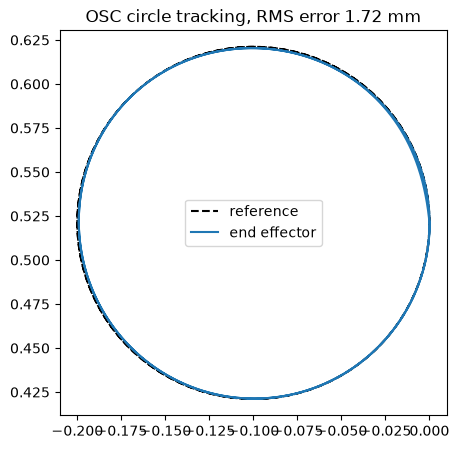

In [2]:
model, data = torque_panda()
quat_d = np.zeros(4); mujoco.mju_mat2Quat(quat_d, data.site("ee").xmat)
center = data.site("ee").xpos.copy() - np.array([0, 0.1, 0])
Kp = np.r_[[400] * 3, [200] * 3]; Kd = 2 * np.sqrt(Kp)
traj, ref, frames = [], [], []
with mujoco.Renderer(model, 240, 320) as r:
    while data.time < 4:
        x_d, xd_d, xdd_d = circle(data.time, center)
        data.ctrl[:7] = osc_torque(model, data, x_d, xd_d, xdd_d, quat_d, Kp, Kd); data.ctrl[7] = 255
        mujoco.mj_step(model, data)
        traj.append(data.site("ee").xpos.copy()); ref.append(x_d)
        if len(frames) < data.time * 25:
            cam = mujoco.MjvCamera(); cam.lookat[:] = center; cam.distance, cam.azimuth, cam.elevation = 1.3, 180, -10
            r.update_scene(data, cam); frames.append(r.render())
traj, ref = np.array(traj), np.array(ref)
plt.figure(figsize=(5, 5)); plt.plot(ref[:, 1], ref[:, 2], "k--", label="reference"); plt.plot(traj[:, 1], traj[:, 2], label="end effector")
plt.axis("equal"); plt.legend(); plt.title(f"OSC circle tracking, RMS error {np.sqrt(np.mean(np.sum((traj - ref)[500:] ** 2, 1))) * 1000:.2f} mm"); plt.show()
show_video(frames, fps=25, title="operational space control")

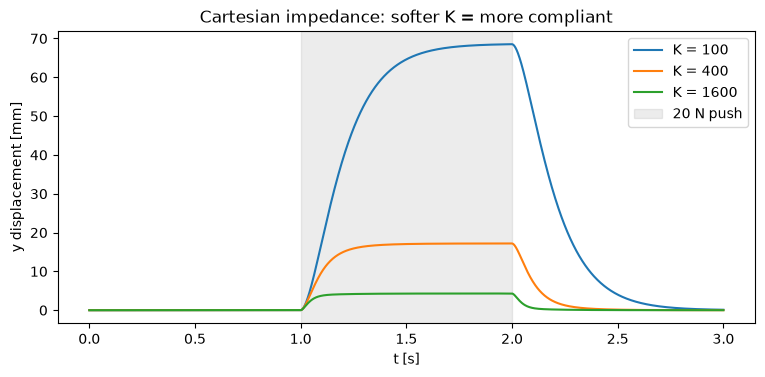

In [3]:
def push_test(stiffness, push=20.0, T=3.0):
    model, data = torque_panda()
    q_d = np.zeros(4); mujoco.mju_mat2Quat(q_d, data.site("ee").xmat)
    x0 = data.site("ee").xpos.copy()
    Kp = np.r_[[stiffness] * 3, [200] * 3]; Kd = 2 * np.sqrt(Kp)
    hand = model.body("hand").id; dx = []
    while data.time < T:
        data.xfrc_applied[hand, :3] = [0, push, 0] if 1.0 < data.time < 2.0 else 0
        data.ctrl[:7] = osc_torque(model, data, x0, np.zeros(3), np.zeros(3), q_d, Kp, Kd); data.ctrl[7] = 255
        mujoco.mj_step(model, data)
        dx.append(data.site("ee").xpos[1] - x0[1])
    return np.array(dx)

plt.figure(figsize=(9, 3.8))
for k in [100, 400, 1600]:
    dx = push_test(k)
    plt.plot(np.arange(len(dx)) * 0.002, dx * 1000, label=f"K = {k}")
plt.axvspan(1, 2, color="gray", alpha=0.15, label="20 N push")
plt.xlabel("t [s]"); plt.ylabel("y displacement [mm]"); plt.legend(); plt.title("Cartesian impedance: softer K = more compliant"); plt.show()